# Deliverable 3b: Predictive Risk Model & Model Performance
**Project:** The Role of Data Analytics in Identifying Revenue Collection Leakages at Forbes Border Post, Zimbabwe
**Notebook:** 03 – Modelling and evaluation

**Why this notebook exists:** the proposal's *Modelling and Evaluation* phase asks us to *"develop analytical measures and risk indicators to identify transactions with unusual differences between declared and assessed revenue"*. The supervisor's brief asks for **model performance** in the final report.

**The question the model answers:** *Before a shipment is cleared, can we predict which declarations are likely to be under-declared, so that inspections are sent where the revenue gap actually is?*

* **Target variable:** `Has_Revenue_Gap` (1 if customs assessed more revenue than was declared, else 0).
* **Benchmark to beat:** the current `Risk_Category` (Low / Medium / High) system, which notebook 02 showed points the wrong way.
* **How we judge success:** statistical metrics (ROC-AUC, PR-AUC), tested on data the model did not see, **plus** a business test: *with the same number of inspections, how much more of the gap would be caught?*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict, permutation_test_score
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix, precision_score, recall_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df = pd.read_csv('../data/processed/cleaned_customs_transactions.csv')
df['Declaration_Date'] = pd.to_datetime(df['Declaration_Date'])
# Sort by time so 'importer history' features only use the past
df = df.sort_values(['Declaration_Date', 'Declaration_ID']).reset_index(drop=True)

# Target: did customs assess more revenue than the importer declared?
df['Target'] = (df['Has_Revenue_Gap'] == 'Yes').astype(int)
y = df['Target']
print(f"{len(df)} declarations | {y.sum()} with a revenue gap ({y.mean() * 100:.1f}% base rate)")

480 declarations | 123 with a revenue gap (25.6% base rate)


## 1. Feature engineering: only information available *before* clearance
A risk model is only useful if it can be applied **when the shipment arrives**, before anyone has inspected or assessed it. So we must not feed it anything that is only known afterwards. Doing so is called **data leakage**: the model looks brilliant in testing but is useless in practice.

In [2]:
# --- Features available BEFORE clearance (what an officer knows when deciding whether to inspect) ---
df['Log_Declared_Value'] = np.log(df['Declared_Customs_Value_USD'])
df['Has_Excise'] = (df['Declared_Excise_USD'] > 0).astype(int)
df['Month_Num'] = df['Declaration_Date'].dt.month

# Importer history: computed ONLY from that importer's earlier declarations (no peeking into the future)
grp = df.groupby('Importer_ID')
df['Importer_Prior_Declarations'] = grp.cumcount()
df['Importer_Prior_Gaps'] = grp['Target'].transform(lambda s: s.shift(1).fillna(0).cumsum())
base_rate = y.mean()
df['Importer_Prior_Gap_Rate'] = np.where(df['Importer_Prior_Declarations'] > 0,
                                         df['Importer_Prior_Gaps'] / df['Importer_Prior_Declarations'].clip(lower=1),
                                         base_rate)   # first-time importers get the average rate

cat_features = ['Risk_Category', 'Country_of_Origin', 'Commodity_Description']
num_features = ['Log_Declared_Value', 'Has_Excise', 'Month_Num',
                'Importer_Prior_Declarations', 'Importer_Prior_Gap_Rate']
X = df[cat_features + num_features]

# Deliberately EXCLUDED (they are only known after customs has acted, so using them would be 'data leakage'):
excluded = ['Assessed_* columns', 'Potential_Revenue_Gap_USD', 'Inspection_Conducted', 'Offence_Detected',
            'Offence_Type', 'Additional_Revenue_Recovered_USD', 'Payment_Status']
print("Features used:", cat_features + num_features)
print("Excluded (post-clearance / leakage):", excluded)

Features used: ['Risk_Category', 'Country_of_Origin', 'Commodity_Description', 'Log_Declared_Value', 'Has_Excise', 'Month_Num', 'Importer_Prior_Declarations', 'Importer_Prior_Gap_Rate']
Excluded (post-clearance / leakage): ['Assessed_* columns', 'Potential_Revenue_Gap_USD', 'Inspection_Conducted', 'Offence_Detected', 'Offence_Type', 'Additional_Revenue_Recovered_USD', 'Payment_Status']


### Interpretation: the feature set
* **Used:** the risk category, country of origin, commodity, size of the declaration (log of declared value), whether excise applies, the month, and the **importer's own track record**.
* **Importer history is built without looking ahead.** For each declaration it only counts that importer's *earlier* declarations. A first-time importer is given the average gap rate (25.6%).
* **Excluded:** everything customs only knows *after* acting (the assessed values, the gap itself, inspection and offence outcomes, recovery and payment status). Including, for example, `Assessed_Total_Revenue_USD` would make the model "predict" the gap almost perfectly, but only because it is being shown the answer.

## 2. Which factors are genuinely linked to under-declaration?
Before modelling, we test each factor on its own. A **chi-square test** asks: *are the differences in gap rates between groups bigger than random chance would produce?* A **p-value below 0.05** means the difference is unlikely to be chance.

In [3]:
# Which single factors are genuinely associated with under-declaration? (chi-square test of independence)
rows = []
for col in ['Risk_Category', 'Country_of_Origin', 'Commodity_Description', 'Month_Num', 'Has_Excise']:
    table = pd.crosstab(df[col], y)
    chi2, p, dof, _ = chi2_contingency(table)
    rates = (table[1] / table.sum(axis=1) * 100)
    rows.append({'Factor': col, 'Chi2': round(chi2, 2), 'df': dof, 'p_value': round(p, 4),
                 'Significant at 5%': 'Yes' if p < 0.05 else 'No',
                 'Gap rate range (%)': f"{rates.min():.0f} – {rates.max():.0f}"})

# Importer history: does a past gap predict a future one?
hist = df[df['Importer_Prior_Declarations'] > 0]
prior_any = (hist['Importer_Prior_Gaps'] > 0)
table = pd.crosstab(prior_any, hist['Target'])
chi2, p, dof, _ = chi2_contingency(table)
rows.append({'Factor': 'Importer had a previous gap', 'Chi2': round(chi2, 2), 'df': dof, 'p_value': round(p, 4),
             'Significant at 5%': 'Yes' if p < 0.05 else 'No',
             'Gap rate range (%)': f"{hist.loc[~prior_any, 'Target'].mean() * 100:.0f} (no prior gap) vs "
                                   f"{hist.loc[prior_any, 'Target'].mean() * 100:.0f} (prior gap)"})
display(pd.DataFrame(rows))

# Are 'repeat under-declarers' more common than pure chance would produce?
rng = np.random.default_rng(RANDOM_STATE)
n_per_importer = df.groupby('Importer_ID').size().values
observed_repeat = (df.groupby('Importer_ID')['Target'].sum() >= 3).sum()
simulated = np.array([(rng.binomial(n_per_importer, base_rate) >= 3).sum() for _ in range(10000)])
print(f"\nImporters with 3+ under-declared shipments: observed = {observed_repeat}, "
      f"expected by pure chance = {simulated.mean():.1f} (p = {(simulated >= observed_repeat).mean():.2f})")

,Factor,Chi2,df,p_value,Significant at 5%,Gap rate range (%)
0,Risk_Category,11.25,2,0.0036,Yes,17 – 33
1,Country_of_Origin,4.25,5,0.5142,No,19 – 33
2,Commodity_Description,8.00,9,0.5343,No,17 – 38
3,Month_Num,11.80,11,0.3792,No,13 – 38
4,Has_Excise,0.08,1,0.7766,No,24 – 26
5,Importer had a previous gap,1.30,1,0.2549,No,29 (no prior gap) vs 23 (prior gap)



Importers with 3+ under-declared shipments: observed = 21, expected by pure chance = 20.2 (p = 0.45)


### Interpretation: only the risk category carries a real signal (important)
* **Risk category is significant (p = 0.004).** Gap rates range from 17% (High) to 33% (Low). This confirms the main finding of notebook 02: the risk profile is linked to under-declaration, **but in reverse**.
* **Country, commodity, month and excise are *not* significant** (p = 0.38 to 0.78). The differences seen in notebook 02 (e.g. plastic products 38% vs food products 17%, South Africa 33% vs Mozambique 19%) are **within the range random chance could produce** with groups of this size (37–94 declarations each). They are leads worth monitoring, not proven risk factors.
* **Importer history does not predict future gaps.** Importers with a previous gap had a gap on 23% of later shipments, compared with 29% for those without (not significant). The **21 "repeat" importers (3+ gaps)** are almost exactly the **20.2 that pure chance would produce** (p = 0.45). In this data, under-declaration behaves as if it is spread across importers, not concentrated in a group of persistent offenders.

**Implication:** this corrects some earlier claims. Country, commodity and importer "watchlists" should be presented as **descriptive patterns, not statistically proven risk drivers**. The one robust, actionable signal is that **Low-risk shipments are under-declared more often than High-risk ones**. (These findings partly reflect the simulated data. In real ZIMRA data, importer history usually *is* predictive, so it should be re-tested on real data.)

## 3. Benchmark: how good is the current risk category as a predictor?
**ROC-AUC** measures how well a score ranks risky declarations above non-risky ones. **0.5 = coin toss, 1.0 = perfect.** A value *below* 0.5 means the ranking is systematically backwards.

In [4]:
# How well does the CURRENT risk category rank declarations by likelihood of a gap?
risk_score_current = df['Risk_Category'].map({'Low': 1, 'Medium': 2, 'High': 3})   # current logic: High = most risky
auc_current = roc_auc_score(y, risk_score_current)
auc_inverted = roc_auc_score(y, -risk_score_current)

print(f"ROC-AUC of current risk category (High = riskiest): {auc_current:.3f}")
print(f"ROC-AUC if the categories were reversed (Low = riskiest): {auc_inverted:.3f}")
print("(0.5 = no better than a coin toss; 1.0 = perfect ranking)")

ROC-AUC of current risk category (High = riskiest): 0.408
ROC-AUC if the categories were reversed (Low = riskiest): 0.592
(0.5 = no better than a coin toss; 1.0 = perfect ranking)


### Interpretation: the current system is worse than random
* The current risk category scores a **ROC-AUC of 0.41**, which is **below 0.5**. Prioritising inspections by "High risk first" ranks declarations **worse than picking them at random**, because the categories are inversely related to under-declaration.
* Simply **reversing the order** gives an AUC of **0.59**. That is better than chance, but still a weak predictor.

## 4. Model comparison
Four models are compared, from simplest to most complex:
* **A.** Logistic regression using **only the risk category**: in effect, *re-weighting* the existing categories by how often each one is actually under-declared.
* **B.** Logistic regression with **all features**.
* **C.** Random forest with all features.
* **D.** Gradient boosting with all features.

With only 480 declarations, a single train/test split would be unreliable, so we use **5-fold cross-validation repeated 5 times** (25 different splits) and report the average and spread. **PR-AUC** (precision-recall) is also shown. It focuses on how well the gap cases are found, and its "random" level is the base rate (0.256).

In [5]:
def make_pipeline(model, cats=cat_features, nums=num_features):
    pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cats),
                             ('num', StandardScaler(), nums)] if nums else
                            [('cat', OneHotEncoder(handle_unknown='ignore'), cats)])
    return Pipeline([('prep', pre), ('model', model)])

candidates = {
    'A. Logistic regression – risk category only': make_pipeline(
        LogisticRegression(max_iter=2000), cats=['Risk_Category'], nums=[]),
    'B. Logistic regression – all features': make_pipeline(
        LogisticRegression(max_iter=2000, C=0.5)),
    'C. Random forest – all features': make_pipeline(
        RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=RANDOM_STATE)),
    'D. Gradient boosting – all features': make_pipeline(
        GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=RANDOM_STATE)),
}

# 5-fold cross-validation repeated 5 times = 25 train/test splits, for a stable estimate on a small dataset
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
results = []
for name, pipe in candidates.items():
    sc = cross_validate(pipe, X, y, cv=cv, scoring=['roc_auc', 'average_precision'])
    results.append({'Model': name,
                    'ROC-AUC (mean)': sc['test_roc_auc'].mean(), 'ROC-AUC (sd)': sc['test_roc_auc'].std(),
                    'PR-AUC (mean)': sc['test_average_precision'].mean()})
results = pd.DataFrame(results).set_index('Model')
results.loc['Current risk category (no model)'] = [auc_current, np.nan, average_precision_score(y, risk_score_current)]
results.loc['Random guessing'] = [0.5, np.nan, base_rate]
display(results.round(3))

,ROC-AUC (mean),ROC-AUC (sd),PR-AUC (mean)
Model,,,
A. Logistic regression – risk category only,0.587,0.059,0.307
B. Logistic regression – all features,0.542,0.059,0.307
C. Random forest – all features,0.525,0.058,0.308
D. Gradient boosting – all features,0.517,0.053,0.289
Current risk category (no model),0.408,NaN,0.228
Random guessing,0.500,NaN,0.256


### Interpretation: model performance
| Model | ROC-AUC | Verdict |
|---|---|---|
| **A. Risk category re-weighted** | **0.587** (±0.06) | **Best and most reliable** |
| B. Logistic, all features | 0.542 | Slightly worse than A |
| C. Random forest | 0.525 | Close to random |
| D. Gradient boosting | 0.517 | Close to random |
| Current risk category | 0.408 | Worse than random |

* **The simplest model wins.** Adding country, commodity, value, month and importer history makes the models **worse**, not better. Those features carry no real signal (section 2), so the complex models end up fitting noise. This is **overfitting**, and a good example of why more complex models are not automatically better.
* **Overall predictive power is modest** (AUC ≈ 0.59). The available fields cannot predict under-declaration precisely. They can only **tilt the odds**, which is still useful for directing a limited inspection budget (section 5).
* **PR-AUC:** all models score about 0.30 vs 0.26 for random, a modest improvement in finding gap cases. The current system scores 0.23, *below* random.

In [6]:
# Is the best models' performance better than chance? Permutation test: shuffle the target many times and refit.
for name in ['A. Logistic regression – risk category only', 'B. Logistic regression – all features']:
    score, perm_scores, p = permutation_test_score(candidates[name], X, y, scoring='roc_auc',
                                                   cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                                                   n_permutations=300, random_state=RANDOM_STATE)
    print(f"{name}: ROC-AUC = {score:.3f}, chance level ≈ {perm_scores.mean():.3f}, p-value = {p:.3f}")

A. Logistic regression – risk category only: ROC-AUC = 0.592, chance level ≈ 0.498, p-value = 0.003
B. Logistic regression – all features: ROC-AUC = 0.548, chance level ≈ 0.501, p-value = 0.110


### Interpretation: is the improvement real or luck?
A **permutation test** shuffles the target 300 times and refits the model each time, to see what AUC is achievable by pure luck.
* **Model A: p = 0.003.** Its AUC of 0.59 is **very unlikely to be luck**, so the re-weighted risk signal is genuine.
* **Model B: p = 0.11.** Its AUC is **not significantly better than chance**. The extra features add noise, not information.

This is the statistical evidence for recommending Model A's logic over the current rule.

In [7]:
# Realistic test: train on Jan–Sep, predict Oct–Dec (the model never sees the future)
train = df['Declaration_Date'] < '2025-10-01'
test = ~train
print(f"Train: {train.sum()} declarations (Jan–Sep) | Test: {test.sum()} declarations (Oct–Dec)")

holdout = []
for name in ['A. Logistic regression – risk category only', 'B. Logistic regression – all features',
             'C. Random forest – all features']:
    pipe = candidates[name].fit(X[train], y[train])
    p = pipe.predict_proba(X[test])[:, 1]
    holdout.append({'Model': name, 'ROC-AUC': roc_auc_score(y[test], p), 'PR-AUC': average_precision_score(y[test], p)})
holdout.append({'Model': 'Current risk category (no model)', 'ROC-AUC': roc_auc_score(y[test], risk_score_current[test]),
                'PR-AUC': average_precision_score(y[test], risk_score_current[test])})
display(pd.DataFrame(holdout).set_index('Model').round(3))

Train: 358 declarations (Jan–Sep) | Test: 122 declarations (Oct–Dec)


,ROC-AUC,PR-AUC
Model,,
A. Logistic regression – risk category only,0.582,0.364
B. Logistic regression – all features,0.620,0.411
C. Random forest – all features,0.572,0.359
Current risk category (no model),0.348,0.253


### Interpretation: time-based test (train on Jan–Sep, predict Oct–Dec)
This mimics real use: the model learns from the past and is tested on later months it has never seen.
* Both logistic models stay **above 0.58** on the unseen Oct–Dec data. The current risk category scores **0.35**, again **worse than random**. The conclusion holds over time.
* Model B scores slightly higher here (0.62) than Model A (0.58), but this test uses only 122 declarations, so one quarter's result is noisy. The 25-split cross-validation and the permutation test above are the more reliable evidence, and they favour Model A.

## 5. Business evaluation: what difference would the model make?
Statistical scores mean little to management. The real question is: **with the same number of inspections as in 2025 (156), how much of the revenue gap would each targeting strategy catch?**

Every declaration is scored by a model that **did not see it during training** (out-of-fold prediction). The top 156 are then "inspected".

In [8]:
# Business test: with the SAME number of inspections as today (156), how much of the gap would each strategy catch?
budget = int((df['Inspection_Conducted'] == 'Yes').sum())
total_gap = df['Potential_Revenue_Gap_USD'].sum()
total_cases = y.sum()

# Out-of-fold scores: each declaration is scored by a model that never saw it during training
oof = {name: cross_val_predict(candidates[name], X, y, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                               method='predict_proba')[:, 1]
       for name in ['A. Logistic regression – risk category only', 'B. Logistic regression – all features']}

def capture(score, n_sims=200):
    # Inspect the top-`budget` declarations by score; ties broken at random (averaged over simulations)
    rng = np.random.default_rng(RANDOM_STATE)
    caught_gap, caught_cases = [], []
    for _ in range(n_sims):
        order = np.lexsort((rng.random(len(score)), -np.asarray(score)))[:budget]
        caught_gap.append(df['Potential_Revenue_Gap_USD'].values[order].sum())
        caught_cases.append(y.values[order].sum())
    return np.mean(caught_cases), np.mean(caught_gap)

strategies = {
    'Actual inspections in 2025': (df.loc[df['Inspection_Conducted'] == 'Yes', 'Target'].sum(),
                                   df.loc[df['Inspection_Conducted'] == 'Yes', 'Potential_Revenue_Gap_USD'].sum()),
    'Random selection': capture(np.zeros(len(df))),
    'Current risk rule (High first)': capture(risk_score_current.values),
    'Model A (risk category re-weighted)': capture(oof['A. Logistic regression – risk category only']),
    'Model B (all features)': capture(oof['B. Logistic regression – all features']),
}
budget_table = pd.DataFrame(strategies, index=['Gap cases caught', 'Gap USD caught']).T
budget_table['% of gap cases'] = budget_table['Gap cases caught'] / total_cases * 100
budget_table['% of gap USD'] = budget_table['Gap USD caught'] / total_gap * 100
budget_table['Hit rate % (cases / inspections)'] = budget_table['Gap cases caught'] / budget * 100
print(f"Inspection budget: {budget} declarations ({budget / len(df) * 100:.1f}% of all)")
display(budget_table.round(1))

Inspection budget: 156 declarations (32.5% of all)


,Gap cases caught,Gap USD caught,% of gap cases,% of gap USD,Hit rate % (cases / inspections)
Actual inspections in 2025,36.0,11716.3,29.3,34.7,23.1
Random selection,40.4,11203.4,32.8,33.1,25.9
Current risk rule (High first),29.5,8361.0,24.0,24.7,18.9
Model A (risk category re-weighted),47.2,14432.1,38.4,42.7,30.3
Model B (all features),45.0,12692.6,36.6,37.6,28.8


### Interpretation: same effort, more revenue found (key result for the report)
| Strategy (156 inspections) | Gap cases caught | Share of gap $ caught |
|---|---|---|
| **Model A: risk category re-weighted** | **47** | **42.7% ($14,432)** |
| Model B: all features | 45 | 37.6% |
| Actual inspections in 2025 | 36 | 34.7% ($11,716) |
| Random selection | 40 | 33.1% |
| Current rule applied strictly (High first) | 30 | 24.7% |

* **Model A catches about $2,700 more of the gap (+23%)** and **11 more under-declared shipments** than the actual 2025 inspections, **with no extra inspections**. The share of inspections that find an under-declaration rises from **23% to 30%**.
* **The 2025 inspections were only marginally better than random selection.** Applying the risk rule strictly (High first) would have done **even worse** (24.7%). Officers' discretion in inspecting some Low and Medium shipments partly rescued it.
* **What Model A means in practice:** treat today's **Low-risk** declarations as the **highest priority** for checks, then Medium, then High. The model's predicted gap probability is **32.8% for Low, 21.0% for Medium and 17.8% for High** (see below).

**Implication for management:** better targeting of the **existing** inspection budget would raise detection and recovered revenue straight away. Section 1 of notebook 02 showed that 85% of a detected gap is recovered, so catching about $2,700 more gap would mean roughly **$2,300 more revenue recovered per year** at this post, even with this weak model. Richer data (section 6) should increase this considerably.

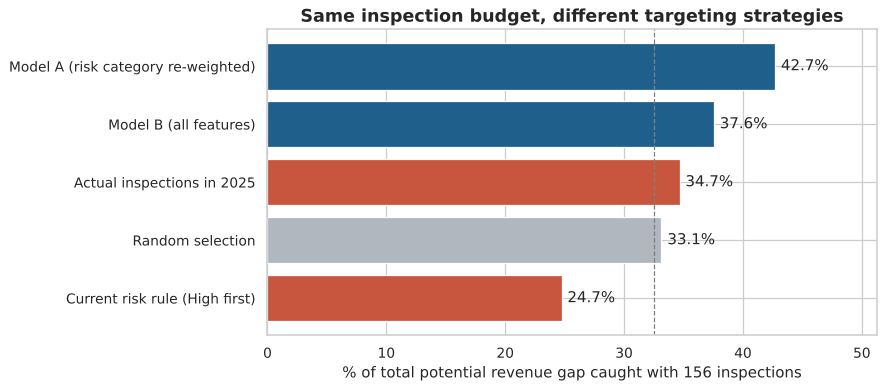

In [9]:
plot_df = budget_table['% of gap USD'].sort_values()
colors = ['#C8553D' if 'Actual' in i or 'Current' in i else ('#B0B7BF' if 'Random' in i else '#1F5F8B') for i in plot_df.index]
plt.figure(figsize=(10, 4.5))
bars = plt.barh(plot_df.index, plot_df.values, color=colors)
for b in bars:
    plt.text(b.get_width() + 0.5, b.get_y() + b.get_height() / 2, f"{b.get_width():.1f}%", va='center')
plt.axvline(budget / len(df) * 100, color='grey', linestyle='--', linewidth=1)
plt.xlabel('% of total potential revenue gap caught with 156 inspections')
plt.title('Same inspection budget, different targeting strategies', fontsize=14, fontweight='bold')
plt.xlim(0, max(plot_df.values) * 1.2)
plt.tight_layout()
plt.savefig('../reports/model_targeting_comparison.png', bbox_inches='tight')
plt.show()

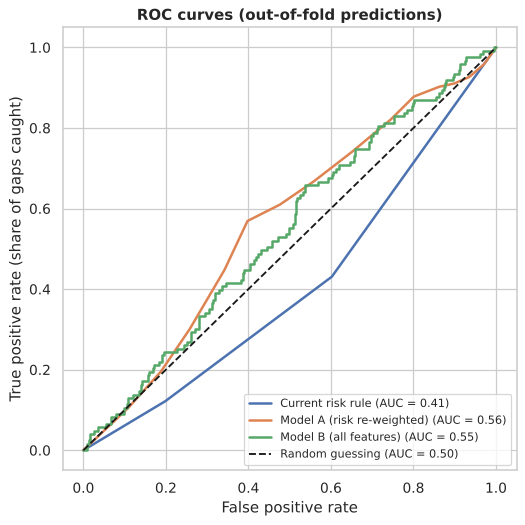

In [10]:
plt.figure(figsize=(6, 6))
for name, score in [('Current risk rule', risk_score_current.values),
                    ('Model A (risk re-weighted)', oof['A. Logistic regression – risk category only']),
                    ('Model B (all features)', oof['B. Logistic regression – all features'])]:
    fpr, tpr, _ = roc_curve(y, score)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y, score):.2f})", linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.50)')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate (share of gaps caught)')
plt.title('ROC curves (out-of-fold predictions)', fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('../reports/model_roc_curves.png', bbox_inches='tight')
plt.show()

### Reading the ROC curve
The curve shows the share of gap cases caught (vertical axis) against the share of clean declarations wrongly flagged (horizontal axis), over every possible cut-off. The further above the dashed diagonal, the better.
* **Model A** sits consistently above the diagonal.
* **The current risk rule sits *below* the diagonal**, which is the visual proof that it ranks declarations backwards.

## 6. What drives the predictions?

Model A – predicted probability of a revenue gap by current risk category:


,Predicted gap probability (%)
Low,32.8
Medium,21.0
High,17.8


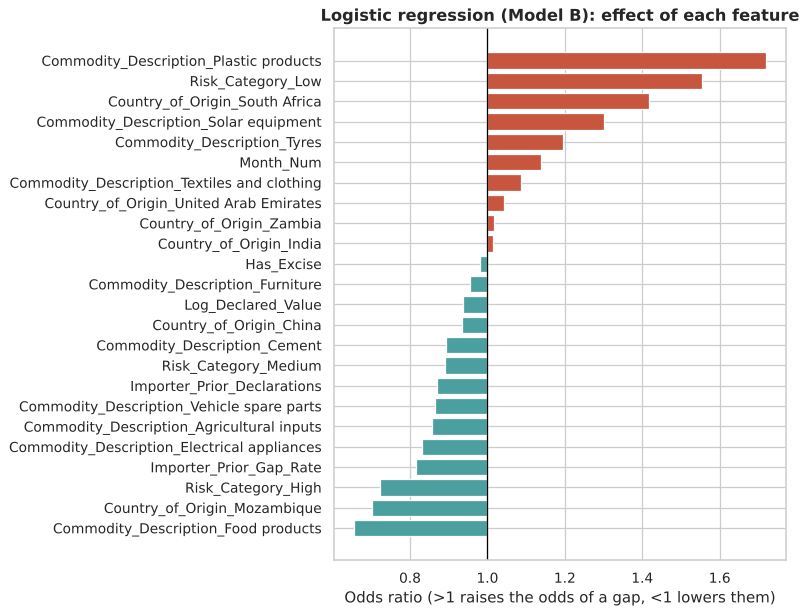

In [11]:
# What does the full logistic regression actually learn? (fitted on all data, for interpretation only)
final_B = candidates['B. Logistic regression – all features'].fit(X, y)
names = final_B.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(final_B.named_steps['model'].coef_[0], index=names)
coefs.index = coefs.index.str.replace('cat__', '').str.replace('num__', '')
odds = np.exp(coefs).sort_values()
plt.figure(figsize=(9, 7))
plt.barh(odds.index, odds.values - 1, left=1, color=np.where(odds.values > 1, '#C8553D', '#4C9F9F'))
plt.axvline(1, color='black', linewidth=1)
plt.xlabel('Odds ratio (>1 raises the odds of a gap, <1 lowers them)')
plt.title('Logistic regression (Model B): effect of each feature', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

final_A = candidates['A. Logistic regression – risk category only'].fit(X, y)
probs = pd.Series(final_A.predict_proba(pd.DataFrame({'Risk_Category': ['Low', 'Medium', 'High']}).reindex(columns=X.columns))[:, 1],
                  index=['Low', 'Medium', 'High'])
print("Model A – predicted probability of a revenue gap by current risk category:")
display((probs * 100).round(1).to_frame('Predicted gap probability (%)'))

### Interpretation: feature effects
* **Odds ratios** show how each feature changes the odds of a gap relative to the reference: above 1 raises the risk, below 1 lowers it.
* **Model B** points in the same directions as notebook 02. Plastic products, Low risk category, South Africa, solar equipment and tyres raise the odds. Food products, Mozambique and High risk category lower them. However, section 2 showed that **only the risk-category effect is statistically reliable**, so the country and commodity bars should be treated as **hypotheses to test on more data**.
* **Importer prior gap rate has an odds ratio below 1.** A past gap slightly *lowers* the predicted risk here, which confirms that importer history is not useful in this dataset.
* **Model A's predicted probabilities** are simply the observed gap rate of each category. That is why it is easy to explain and easy to put into practice.

In [12]:
# Save the risk scores so they can be used in Power BI (e.g. a 'Model risk score' column / slicer)
df['Model_Gap_Probability'] = oof['A. Logistic regression – risk category only'].round(4)
df[['Declaration_ID', 'Model_Gap_Probability']].to_csv('../data/processed/model_risk_scores.csv', index=False)
results.round(3).to_csv('../reports/model_performance.csv')
budget_table.round(1).to_csv('../reports/model_targeting_comparison.csv')
print("Saved: data/processed/model_risk_scores.csv, reports/model_performance.csv, reports/model_targeting_comparison.csv")

Saved: data/processed/model_risk_scores.csv, reports/model_performance.csv, reports/model_targeting_comparison.csv


## Summary: model performance for the final report

**Objective:** predict, before clearance, which declarations are likely to be under-declared.

**Result:**
* **Best model:** logistic regression on the risk category (Model A), effectively a **recalibrated risk ranking**.
  * **ROC-AUC 0.59** (25-split cross-validation, ±0.06; permutation test **p = 0.003**).
  * **0.58 on the unseen Oct–Dec period**.
  * The **current risk system scores 0.41**, worse than random.
* **Business impact:** with the same 156 inspections, Model A would catch **42.7% of the gap ($14.4K) vs 34.7% ($11.7K) today**, about **+23% more gap detected** and **11 more under-declarations** found.
* **More complex models (random forest, gradient boosting, full logistic) did not help** (AUC 0.52–0.54, not significant). Country, commodity, value, month and importer history carry **no statistically significant signal** in this dataset.

**Recommendations arising from the model:**
1. **Recalibrate risk channels now.** Raise inspection priority for Low-risk declarations, which are under-declared most often.
2. **Keep a random-inspection component**, so the risk model keeps receiving unbiased data to learn from. Today, offences are only observed where officers chose to look.
3. **Enrich the data to improve the model:** unit values and quantities, weights, declared vs reference prices per HS code, clearing agent, and multi-year importer history. Valuation offences dominate (notebook 02), so **unit-price comparisons** are the most promising predictor.
4. **Re-estimate the model regularly** (e.g. quarterly) as patterns change.

**Limitations:**
* The data is simulated, with only 480 declarations and 123 gap cases, so the estimates are uncertain (±0.06 AUC).
* The target is the **assessed-vs-declared gap**, which itself depends on customs assessments; under-declarations customs never assessed are invisible.
* Predictive power is modest. The model **tilts the odds**; it does not identify fraud.

*Outputs saved:* `data/processed/model_risk_scores.csv` (a gap probability per declaration, which can be loaded into Power BI), `reports/model_performance.csv`, `reports/model_targeting_comparison.csv`, `reports/model_targeting_comparison.png`, `reports/model_roc_curves.png`.